In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set plot style for better visuals
plt.style.use('seaborn-v0_8') 
sns.set_palette("husl")


In [2]:
# 1. Import the Preprocessing module
# This will trigger Loaddata.py to run, then Preprocessing.py to run
import Preprocessing

# 2. Extract the cleaned dataframe 'df' from the Preprocessing module
# Since df was defined in those files, it is now a property of the module
df = Preprocessing.df

# 3. Verify the data is loaded and cleaned
print("✅ Data successfully imported from Preprocessing.py")
print(f"Dataset Shape: {df.shape}")
df.head()


Dataset Loaded Successfully!
   Unnamed: 0            timestamp    TP2    TP3     H1  DV_pressure  \
0           0  2020-02-01 00:00:00 -0.012  9.358  9.340       -0.024   
1          10  2020-02-01 00:00:10 -0.014  9.348  9.332       -0.022   
2          20  2020-02-01 00:00:19 -0.012  9.338  9.322       -0.022   
3          30  2020-02-01 00:00:29 -0.012  9.328  9.312       -0.022   
4          40  2020-02-01 00:00:39 -0.012  9.318  9.302       -0.022   

   Reservoirs  Oil_temperature  Motor_current  COMP  DV_eletric  Towers  MPG  \
0       9.358           53.600         0.0400   1.0         0.0     1.0  1.0   
1       9.348           53.675         0.0400   1.0         0.0     1.0  1.0   
2       9.338           53.600         0.0425   1.0         0.0     1.0  1.0   
3       9.328           53.425         0.0400   1.0         0.0     1.0  1.0   
4       9.318           53.475         0.0400   1.0         0.0     1.0  1.0   

   LPS  Pressure_switch  Oil_level  Caudal_impulses  
0  

c:\Users\user\OneDrive\Desktop\guvi\Industrial Compressor\Preprocessing.py:29: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill', inplace=True)


✅ Step 2.5: Numerical features normalized (Range 0 to 1).

PREPROCESSING COMPLETE
Final Dataset Shape: (1516948, 16)

First 5 rows of processed data:
                       Unnamed: 0       TP2       TP3        H1  DV_pressure  \
timestamp                                                                      
2020-02-01 00:00:00  0.000000e+00  0.001868  0.901379  0.908175     0.000810   
2020-02-01 00:00:10  6.592188e-07  0.001681  0.900334  0.907400     0.001013   
2020-02-01 00:00:19  1.318438e-06  0.001868  0.899290  0.906432     0.001013   
2020-02-01 00:00:29  1.977656e-06  0.001868  0.898245  0.905463     0.001013   
2020-02-01 00:00:39  2.636875e-06  0.001868  0.897200  0.904494     0.001013   

                     Reservoirs  Oil_temperature  Motor_current  COMP  \
timestamp                                                               
2020-02-01 00:00:00    0.901752         0.518669       0.002156   1.0   
2020-02-01 00:00:10    0.900709         0.519688       0.002156   1.0 

,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,0.000000e+00,0.001868,0.901379,0.908175,0.000810,0.901752,0.518669,0.002156,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,6.592188e-07,0.001681,0.900334,0.907400,0.001013,0.900709,0.519688,0.002156,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,1.318438e-06,0.001868,0.899290,0.906432,0.001013,0.899666,0.518669,0.002426,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,1.977656e-06,0.001868,0.898245,0.905463,0.001013,0.898623,0.516293,0.002156,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,2.636875e-06,0.001868,0.897200,0.904494,0.001013,0.897580,0.516972,0.002156,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [6]:
!pip install pandas numpy matplotlib seaborn plotly nbformat




   ---------------------------------------- 0/2 [fastjsonschema]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   ---------------------------------------- 2/2 [nbformat]




[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


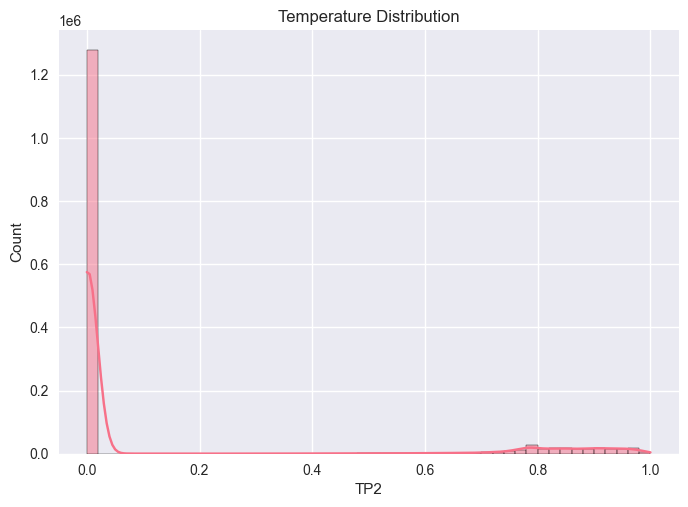

In [11]:
plt.figure()
sns.histplot(df['TP2'], bins=50, kde=True)
plt.title("Temperature Distribution")
plt.show()


In [12]:
# Use first 1000 rows for the plot
sample_df = df.iloc[0:1000].reset_index()

fig = px.line(sample_df, x='timestamp', y='TP2', title="Temperature Behaviour Over Time")
fig.show()


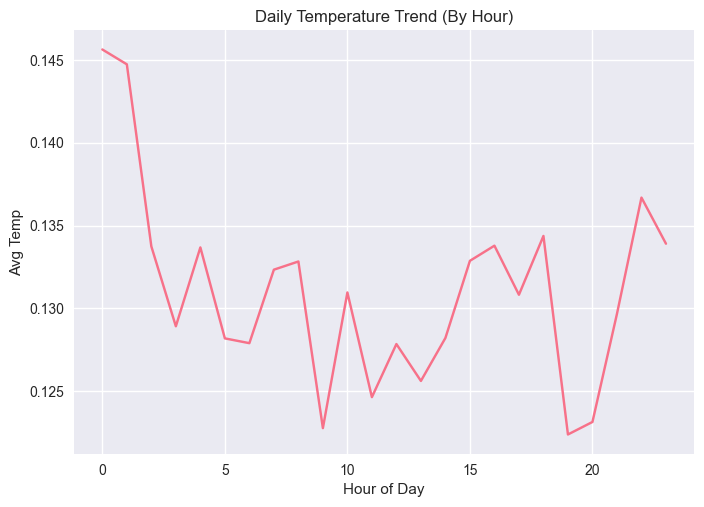

In [13]:
# Get the hour from the index
df['hour'] = df.index.hour
avg_temp = df.groupby('hour')['TP2'].mean()

plt.figure()
plt.plot(avg_temp)
plt.title("Daily Temperature Trend (By Hour)")
plt.xlabel("Hour of Day")
plt.ylabel("Avg Temp")
plt.show()


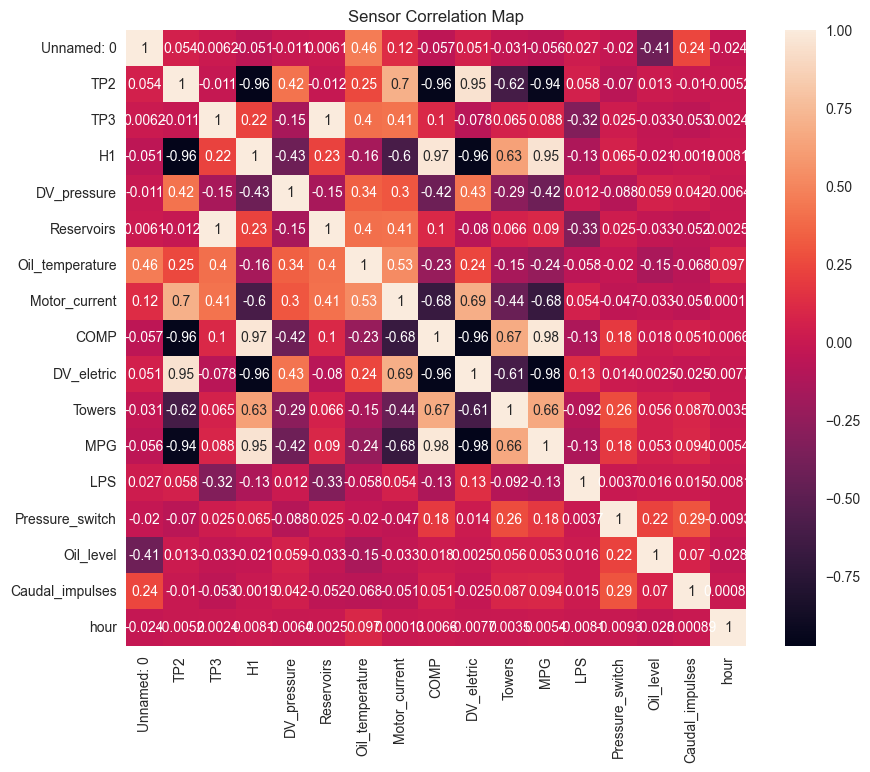

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True)
plt.title("Sensor Correlation Map")
plt.show()


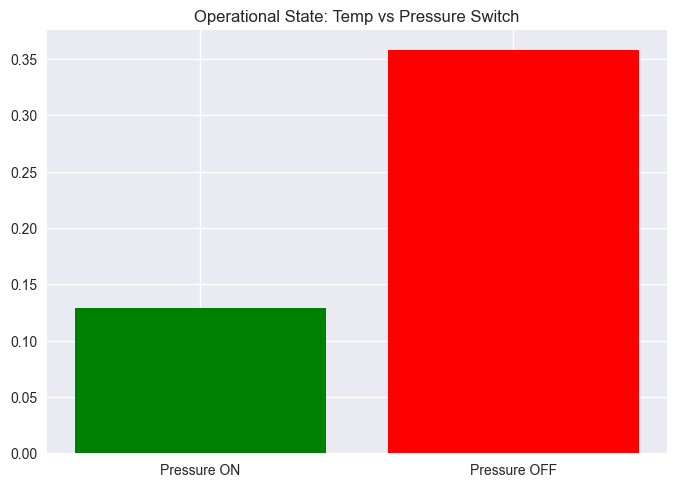

In [15]:
# Find average temp for ON and OFF states
temp_on = df[df['Pressure_switch'] == 1]['TP2'].mean()
temp_off = df[df['Pressure_switch'] == 0]['TP2'].mean()

plt.figure()
plt.bar(['Pressure ON', 'Pressure OFF'], [temp_on, temp_off], color=['green', 'red'])
plt.title("Operational State: Temp vs Pressure Switch")
plt.show()
